# RAG Assignment: Baseline vs. Re-Ranking

**Course:** CL3410 Language Models and Agents · Module 7 (RAG) · **Due:** 19 Oct 2026

This notebook implements two retrieval workflows over the **exact same chunked corpus** of a single PDF and compares them:

| | Pipeline 1 (baseline) | Pipeline 2 (re-ranking) |
|---|---|---|
| Retrieve | bi-encoder + FAISS inner product, **top 10** | the **same** top 10 from Pipeline 1 |
| Re-rank | none | cross-encoder scores all 10 (query, chunk) pairs, re-sorted descending |
| To the LLM | top 3 → **Answer 1** | top 3 → **Answer 2** (identical prompt structure) |

```
 OFFLINE:  PDF -> extract & clean -> structure-aware chunks (frozen, hashed) -> bi-encoder -> FAISS IndexFlatIP
 ONLINE :  query -> bi-encoder -> FAISS top-10 --+--> top-3 ---------------------------> prompt -> LLM -> Answer 1
                                                 |
                                                 +--> cross-encoder x 10 -> sort -> top-3 -> prompt -> LLM -> Answer 2
```

**How to run:** create the venv from `requirements.txt`, put keys in `.env` (see `.env.example`), then *Restart kernel and Run All*.
Sections are added stage by stage: setup → document → chunking → index → retrieval/re-ranking → generation → queries → results → failure analysis → latency & scaling → summary.

## 1. Setup

Imports, a single `CONFIG` dict (every tunable lives here), seeds, and the compute device.
Model weights are cached **inside the project** (`.cache/huggingface`, git-ignored) so nothing is written outside the repo folder.

In [1]:
import os, time, json, hashlib, random, platform, statistics, subprocess, re, collections, unicodedata
from pathlib import Path

ROOT = Path.cwd()
# Keep Hugging Face downloads inside the project folder (set before importing sentence-transformers).
os.environ["HF_HOME"] = str(ROOT / ".cache" / "huggingface")
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np
import pandas as pd
import torch
import faiss
import pymupdf
import sentence_transformers
from sentence_transformers import SentenceTransformer, CrossEncoder
from transformers.utils import logging
logging.set_verbosity_error()                 # we only count tokens with the tokenizer, so its length warning is not needed
from dotenv import load_dotenv

load_dotenv(ROOT / ".env")                    # API keys come from .env / environment variables, never from the code

# Every tunable parameter in one place. After the query set is frozen (Stage 6) none of these may change.
CONFIG = {
    "pdf_path": "data/netrunner_comprehensive_rules_v26.03.pdf",
    "doc": {                                  # the single source document; its SHA-256 is checked in Section 2
        "title": "Netrunner Comprehensive Rules v26.03 (Null Signal Games, effective 02 March 2026)",
        "short": "Netrunner CR v26.03",
        "url": "https://access.nullsignal.games/CompRules/Null_Signal_Games_Netrunner_Comprehensive_Rules_v26.03.pdf",
        "sha256": "ffd36071034aeae240cb319b13be1dae1d265c4598b44fbbfb90c86297a4523e",
        "accessed": "2026-10-12",
    },
    "bi_encoder": "sentence-transformers/all-MiniLM-L6-v2",
    "cross_encoder": "cross-encoder/ms-marco-MiniLM-L-6-v2",
    "llm_model": "gemini-3.1-flash-lite",     # Gemini free tier, pinned (higher daily limit than 3.6-flash)
    "thinking_level": "MINIMAL",              # no hidden reasoning: shorter, faster, more predictable answers
    "temperature": 0.0,
    "max_output_tokens": 400,
    "chunk_max_tokens": 220,                  # counted with the bi-encoder tokenizer, header included (its limit is 256)
    "chunk_overlap_tokens": 40,
    "k_retrieve": 10,                         # Pipeline 1 retrieves 10 chunks ...
    "k_final": 3,                             # ... and both pipelines give 3 to the LLM
    "latency_warmup": 3,
    "latency_repeats": 20,
    "seed": 42,
    "device": None,                           # chosen by the benchmark in 1.3, then fixed for all later timings
}

random.seed(CONFIG["seed"]); np.random.seed(CONFIG["seed"]); torch.manual_seed(CONFIG["seed"])

for folder in ["data", "queries", "artifacts/results", "artifacts/figures", "report"]:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)

Project root: /Users/hritikranjan/Desktop/ Folder/SEM 3/LMA/A1_RAG/RAG-BASELINE-VS-RERANKING


### 1.1 Environment record

Latency numbers depend on hardware and library versions, so they are recorded once here.

In [2]:
ENV_INFO = {
    "python": platform.python_version(),
    "machine": platform.platform(),
    "cpu": subprocess.getoutput("sysctl -n machdep.cpu.brand_string"),          # macOS
    "ram_gb": round(int(subprocess.getoutput("sysctl -n hw.memsize")) / 2**30),
    "torch": torch.__version__,
    "sentence_transformers": sentence_transformers.__version__,
    "faiss": faiss.__version__,
    "pymupdf": pymupdf.__version__,
    "mps_available": torch.backends.mps.is_available(),
    "cuda_available": torch.cuda.is_available(),
}
pd.Series(ENV_INFO, name="value").to_frame()

,value
python,3.12.13
machine,macOS-27.0-arm64-arm-64bit
cpu,Apple M4
ram_gb,24
torch,2.14.1
sentence_transformers,6.1.0
faiss,1.15.1
pymupdf,1.28.2
mps_available,True
cuda_available,False


### 1.2 Model smoke test

Both models are loaded and tried once.
- The bi-encoder **silently cuts its input at `max_seq_length` tokens** (256 for all-MiniLM-L6-v2). This is why chunks must stay below 256 tokens (Section 3).
- The cross-encoder returns a raw **logit** (any real number) for each (query, passage) pair, not a probability.

In [3]:
bi_encoder = SentenceTransformer(CONFIG["bi_encoder"], device="cpu")
cross_encoder = CrossEncoder(CONFIG["cross_encoder"], max_length=512, device="cpu")
print("bi-encoder: embedding size", bi_encoder.get_embedding_dimension(), "| max_seq_length", bi_encoder.max_seq_length)

# bi-encoder: normalised vectors, so the inner product equals the cosine similarity
vectors = bi_encoder.encode(["a quick test sentence", "a quick test sentence"], normalize_embeddings=True)
print("vector length (norm):", float(np.linalg.norm(vectors[0])), "| cosine of identical sentences:", float(vectors[0] @ vectors[1]))

# cross-encoder: one score per (query, passage) pair
pairs = [("what is the capital of france", "Paris is the capital and largest city of France."),
         ("what is the capital of france", "Bananas are rich in potassium.")]
print("cross-encoder scores (relevant, irrelevant):", [round(float(s), 2) for s in cross_encoder.predict(pairs)])

bi-encoder: embedding size 384 | max_seq_length 256
vector length (norm): 1.0000001192092896 | cosine of identical sentences: 1.000000238418579
cross-encoder scores (relevant, irrelevant): [7.96, -11.13]


### 1.3 Device choice (benchmarked once, then fixed)

On Apple Silicon, MPS can be slower than CPU for tiny batches such as 10 pairs. The cross-encoder is timed on each available device once, and the faster one is used for every later measurement so that the latency comparison is consistent. Warm-up runs are not counted.

In [4]:
def time_cross_encoder(device, repeats=20):
    model = CrossEncoder(CONFIG["cross_encoder"], max_length=512, device=device)
    pairs = [("what happens if a player cannot pay the cost", "If a player cannot pay a cost, the effect does not resolve. " * 10)] * 10
    for _ in range(3):
        model.predict(pairs)                                   # warm-up
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        model.predict(pairs)
        times.append((time.perf_counter() - start) * 1000)
    return statistics.median(times)

devices = ["cpu"] + (["mps"] if torch.backends.mps.is_available() else []) + (["cuda"] if torch.cuda.is_available() else [])
median_ms = {d: time_cross_encoder(d) for d in devices}
CONFIG["device"] = min(median_ms, key=median_ms.get)
print("median ms for 10 pairs:", {d: round(ms, 1) for d, ms in median_ms.items()})
print("device used from now on:", CONFIG["device"])

# reload both models on that device; these objects are used for the rest of the notebook
bi_encoder = SentenceTransformer(CONFIG["bi_encoder"], device=CONFIG["device"])
cross_encoder = CrossEncoder(CONFIG["cross_encoder"], max_length=512, device=CONFIG["device"])

median ms for 10 pairs: {'cpu': 41.1, 'mps': 23.7}
device used from now on: mps


### 1.4 LLM connection

The LLM (Gemini, free tier) is set up in **Section 6**, after retrieval and re-ranking work. Sections 2-5 need no API key.

## 2. Document (Stage 1)

**Document:** the *Netrunner Comprehensive Rules* (Null Signal Games, v26.03): the formal rules reference of a two-player card game. 99 pages, text-based, single column.

**Why this document**
- **Many exceptions and prohibitions** ("cannot", "unless", "instead", "only if"). Golden rule 1.2.2 even says a "cannot" effect beats a "can" effect. This gives the *exception* and *negation* failure cases.
- **Formal vocabulary a player would not type** (*rez*, *ice*, *trash*, *breach*, *access*). The same words recur in definitions, examples and binding rules, which gives *keyword-trap* and vocabulary-mismatch cases.
- **Right size:** about 550 chunks, so the top 10 is under 2% of the corpus, and gold chunks can still be labelled by hand.
- **Niche game:** the LLM is less likely to answer from memory (checked later with a closed-book control).
- **Clean structure:** hierarchical rule numbers (`4.2.3.`) allow chunking along the document's own structure.

**Licence note:** the PDF is published free by the rules authority, but its licence is not clear, so it is *not* committed to the repo. The cell below downloads it and compares its SHA-256 with the pinned value, so everyone works on the identical file.

In [5]:
import urllib.request

DOC = CONFIG["doc"]
PDF_PATH = ROOT / CONFIG["pdf_path"]

if not PDF_PATH.exists():                       # the PDF is git-ignored, so it is downloaded on the first run
    urllib.request.urlretrieve(DOC["url"], PDF_PATH)

pdf_sha256 = hashlib.sha256(PDF_PATH.read_bytes()).hexdigest()
pdf = pymupdf.open(PDF_PATH)
print(DOC["title"])
print("pages:", len(pdf), "| sha256:", pdf_sha256)
print("same file as the pinned document:", pdf_sha256 == DOC["sha256"])


Netrunner Comprehensive Rules v26.03 (Null Signal Games, effective 02 March 2026)
pages: 99 | sha256: ffd36071034aeae240cb319b13be1dae1d265c4598b44fbbfb90c86297a4523e
same file as the pinned document: True


### 2.1 Reading the PDF

PyMuPDF returns every text span with its font, size and position. The lines are rebuilt from those spans:
- Spans on the same baseline form one line.
- The game's icons (credit, click, ...) are extracted as separate words that would otherwise stick to the number (`1credit`), so they get spaces around them.
- Page numbers at the bottom of each page are dropped.
- Pages 1-3 (change log and table of contents) and page 99 (credits) are left out for **both** pipelines. A table of contents lists every rule number and title without any content, so it would only act as a distractor.

In [6]:
# The game's icons (credit, click, ...) are extracted as separate words, so they are given spaces around them.
ICON_WORDS = {"credit", "click", "recurring", "link", "mu", "trash"}

def clean(text):
    text = unicodedata.normalize("NFKC", text)             # ligatures, non-breaking spaces, ...
    text = re.sub(r"\s+([,.;:)])", r"\1", text)             # no space before punctuation
    return re.sub(r"\s+", " ", text).strip()

def read_page_lines(page, page_no):
    """Rebuild the lines of one page: spans on the same baseline form a line, read left to right."""
    spans = [s for b in page.get_text("dict")["blocks"] for l in b.get("lines", []) for s in l["spans"] if s["text"]]
    spans.sort(key=lambda s: s["origin"][1])
    rows = []
    for s in spans:
        if rows and s["origin"][1] - rows[-1][0]["origin"][1] <= 2:
            rows[-1].append(s)
        else:
            rows.append([s])

    lines = []
    for row in rows:
        row.sort(key=lambda s: s["bbox"][0])
        text, prev_end, prev_icon = "", 0, False
        for s in row:
            is_icon = s["text"] in ICON_WORDS
            if text and (is_icon or prev_icon or s["bbox"][0] - prev_end > 1.5):
                text += " "
            text += s["text"]
            prev_end, prev_icon = max(prev_end, s["bbox"][2]), is_icon
        lines.append({"page": page_no, "x": row[0]["bbox"][0], "y": row[0]["origin"][1],
                      "size": max(s["size"] for s in row), "bold": all("Bold" in s["font"] for s in row if s["text"].strip()),
                      "text": clean(text)})
    return lines

# Pages 1-3 (change log, table of contents) and page 99 (credits) are left out for both pipelines:
# a table of contents lists every rule number and title without any content, so it would only act as a distractor.
FIRST_PAGE, LAST_PAGE = 4, 98

lines = []
for page_no in range(FIRST_PAGE, LAST_PAGE + 1):
    for line in read_page_lines(pdf[page_no - 1], page_no):
        if not (line["text"].isdigit() and line["y"] > 790):     # skip the page number printed at the bottom
            lines.append(line)

print(f"pages {FIRST_PAGE}-{LAST_PAGE} -> {len(lines)} lines")
print("first line:", lines[0]["text"], "| last line:", lines[-1]["text"])


pages 4-98 -> 4634 lines
first line: 1 Game Concepts | last line: 4) Access is complete.


### 2.2 Finding the structure

The layout tells us what each line is:
- bold 14 pt = section (`4 Game Zones`), bold 12 pt = subsection (`4.2 Deck`);
- a line that starts at the left margin with `4.2.3.` begins a numbered **rule**;
- an indented `a.` begins a **sub-rule**, and `Example:` begins an example.

One **rule unit** = one numbered rule *together with its sub-rules and examples*. This matters for the exception failure case: the exception to a rule usually sits in a sub-rule, so it stays attached to its rule unless the size limit forces a split.

In [7]:
RULE = re.compile(r"^(\d+\.\d+\.\d+(?:\.\d+)*)\.(?:\s|$)")     # "4.2.3. text"           -> a numbered rule
SUB = re.compile(r"^(?:[a-z]|[ivx]+)\.\s")                       # "a. text", "ii. text"   -> a sub-rule
STEP = re.compile(r"^(?:\d+|[a-z]|[ivx]+)\)\s")                  # "1) text", "a) text"    -> a step in the appendix lists

def new_unit(rule, page):
    return {"rule": rule, "section": section, "subsection": subsection, "paras": [], "page_start": page, "page_end": page}

units = []
section = subsection = None
prev = None

for line in lines:
    text, page = line["text"], line["page"]
    gap = line["y"] - prev["y"] if prev and prev["page"] == page else 0      # vertical gap to the previous line
    prev = line

    if line["bold"] and line["size"] > 14:                      # "4 Game Zones"
        section, subsection = text, None
        continue
    if line["bold"] and line["size"] > 11.5:                    # "4.2 Deck"
        subsection = text
        units.append(new_unit(None, page))                      # collects the short intro text of the subsection, if any
        continue

    rule = RULE.match(text) if line["x"] < 100 else None        # rule numbers start at the left margin
    if rule:
        units.append(new_unit(rule.group(1), page))

    unit = units[-1]
    unit["page_end"] = page
    starts_paragraph = (rule or not unit["paras"] or gap > 15.5 or text.startswith("Example:")
                        or (line["x"] > 118 and SUB.match(text))
                        or (section.startswith("11 ") and STEP.match(text)))
    if starts_paragraph:
        unit["paras"].append(text)
    else:                                                       # the previous line continues here
        joiner = "" if unit["paras"][-1].endswith("-") else " "
        unit["paras"][-1] += joiner + text

units = [u for u in units if u["paras"]]
print("rule units:", len(units), "| numbered rules:", sum(1 for u in units if u["rule"]))


rule units: 633 | numbered rules: 608


### 2.3 Sanity report

Rule numbers run 1, 2, 3, ... inside each subsection, so a gap in the numbering would show a lost or merged rule. After that, three random pages are shown raw and cleaned side by side.

> 🧑 **Human check:** read the three page comparisons and confirm that no header, footer or table-of-contents text remains and that the rule boundaries look right.

In [8]:
# ---- Headings: sections and how many subsections each has -------------------------------------------------
subsections = collections.OrderedDict()
for u in units:
    subsections.setdefault(u["section"], set()).add(u["subsection"])
for name, subs in subsections.items():
    print(f"{name}: {len(subs)} subsections")

# ---- Rule numbers should run 1, 2, 3, ... inside every subsection; a gap would mean a rule was lost or merged ----
last_number, gaps = {}, 0
for u in units:
    if u["rule"] and u["rule"].count(".") == 2:
        subsection_no, number = u["rule"].rsplit(".", 1)
        if int(number) != last_number.get(subsection_no, 0) + 1:
            gaps += 1
            print("gap before rule", u["rule"])
        last_number[subsection_no] = int(number)
print("\nnumbering gaps:", gaps)

# ---- Leftover junk ------------------------------------------------------------------------------------------
all_text = "\n".join(p for u in units for p in u["paras"])
print("lines that are only a page number:", sum(l.isdigit() for l in all_text.split("\n")))
print("icon words glued to a number (e.g. '1credit'):", len(re.findall(r"\d(?:credit|click|recurring|link|mu|trash)", all_text)))
print("characters of cleaned text:", len(all_text))

# ---- Three random pages: raw PDF text next to the cleaned units that start on that page --------------------
for page_no in sorted(random.Random(CONFIG["seed"]).sample(range(FIRST_PAGE, LAST_PAGE + 1), 3)):
    print("\n" + "=" * 25, f"page {page_no}: RAW", "=" * 25)
    print(pdf[page_no - 1].get_text()[:600])
    print("-" * 25, f"page {page_no}: CLEANED", "-" * 25)
    cleaned = "\n".join(f"[{u['rule'] or '-'}] " + "\n".join(u["paras"]) for u in units if u["page_start"] == page_no)
    print(cleaned[:600])


1 Game Concepts: 21 subsections
2 Parts of a Card: 18 subsections
3 Card Types: 10 subsections
4 Game Zones: 9 subsections
5 Turns: 7 subsections
6 Runs: 9 subsections
7 Accessing Cards and Breaching Servers: 5 subsections
8 Card Manipulation: 8 subsections
9 Abilities: 12 subsections
10 Additional Rules: 14 subsections
11 Appendix: Timing Structure Reference: 6 subsections

numbering gaps: 0
lines that are only a page number: 0
icon words glued to a number (e.g. '1credit'): 0
characters of cleaned text: 355748

========================= page 7: RAW =========================
1.6.3. The players create the bank by gathering all types of tokens described in section 1.9.
1.6.4. Each player takes five credits from the bank, placing the credits in their credit pool.
1.6.5. Each player shuffles their deck.
1.6.6. Each player draws 5 cards from the top of their deck to form their starting hand.
a. After drawing starting hands, the Corp may choose to take a mulligan; then, the Runner may
choose

## 3. Chunking (Stage 2): the frozen corpus

Both pipelines search **one** shared list of chunks. Chunks follow the structure of the document (a fact cut in half cannot be found by any retriever):

1. The base piece is one **rule unit** (a numbered rule with its sub-rules and examples).
2. Consecutive rules of the same subsection are packed into one chunk, up to **220 tokens**.
3. A rule longer than that is split between its paragraphs (or between sentences if one paragraph is too long), **never inside a sentence**. Each new piece repeats the last paragraph(s) of the previous one (up to **40 tokens of overlap**) and its header says which rule it continues.
4. Every chunk starts with a header `[document | section > subsection]`. The header counts toward the 220 tokens.

**Why 220 tokens:** the bi-encoder (all-MiniLM-L6-v2) silently cuts its input at **256 tokens**. A longer chunk would be embedded from its beginning only, while the cross-encoder would read all of it, which would be an unfair comparison. Sizes are counted with the bi-encoder's own tokenizer.

**No tuning for failures:** boundaries come from size and structure only. If a rule and its exception end up in different chunks, that is a real finding for the report.

In [9]:
tokenizer = bi_encoder.tokenizer
MAX_TOKENS, OVERLAP_TOKENS = CONFIG["chunk_max_tokens"], CONFIG["chunk_overlap_tokens"]

def count_tokens(text):
    return len(tokenizer(text)["input_ids"])         # the bi-encoder's own tokenizer, including [CLS] and [SEP]

def header(unit, continued=None):
    """Prefix of every chunk: document, section and subsection (and the rule it continues, for later pieces of a long rule)."""
    text = f"[{CONFIG['doc']['short']} | {unit['section']} > {unit['subsection']}"
    if continued is not None:
        text += " | continued" + (f": rule {continued}" if continued else "")
    return text + "]\n"

def fits(pairs, continued=None):
    """Do these (paragraph, unit) pairs, with their header, fit in one chunk?"""
    return count_tokens(header(pairs[0][1], continued) + "\n".join(p for p, _ in pairs)) <= MAX_TOKENS

def split_long_paragraphs(pairs):
    """A single paragraph that is longer than a chunk is cut into sentences (never in the middle of a sentence)."""
    out = []
    for para, unit in pairs:
        if fits([(para, unit)]):
            out.append((para, unit))
        else:
            out += [(s, unit) for s in re.split(r"(?<=[.!?”])\s+(?=[A-Z“(])", para)]
    return out

def last_paragraphs(pairs):
    """The overlap: trailing paragraphs of a finished chunk, up to OVERLAP_TOKENS tokens."""
    keep, tokens = [], 0
    for para, unit in reversed(pairs):
        tokens += count_tokens(para)
        if tokens > OVERLAP_TOKENS:
            break
        keep.insert(0, (para, unit))
    return keep

chunks = []

def add_chunk(pairs, continued=None):
    units_here = [u for _, u in pairs]
    rules = [u["rule"] for u in units_here if u["rule"]]
    text = header(units_here[0], continued) + "\n".join(p for p, _ in pairs)
    chunks.append({
        "chunk_id": f"C{len(chunks):04d}",
        "text": text,
        "section_path": f"{units_here[0]['section']} > {units_here[0]['subsection']}",
        "rules": f"{rules[0]}-{rules[-1]}" if rules else None,
        "page_start": min(u["page_start"] for u in units_here),
        "page_end": max(u["page_end"] for u in units_here),
        "n_tokens": count_tokens(text),
    })

# Chunk each subsection on its own. Rules are packed together until the chunk is full.
by_subsection = collections.OrderedDict()
for u in units:
    by_subsection.setdefault((u["section"], u["subsection"]), []).append(u)

for subsection_units in by_subsection.values():
    current = []                                            # (paragraph, unit) pairs of the chunk being built
    for u in subsection_units:
        rule_pairs = [(p, u) for p in u["paras"]]
        if fits(current + rule_pairs):                            # the whole rule fits into the current chunk
            current += rule_pairs
            continue
        if current:                                         # it does not: close the current chunk
            add_chunk(current)
            current = []
        if fits(rule_pairs):                                      # the rule fits into a fresh chunk
            current = rule_pairs
            continue
        # the rule is longer than a whole chunk: split it paragraph by paragraph, repeating the last paragraph(s) as overlap
        continued = None                                    # the first piece starts with the rule itself
        for pair in split_long_paragraphs(rule_pairs):
            if current and not fits(current + [pair], continued):
                add_chunk(current, continued)
                continued = u["rule"] or ""                 # later pieces say which rule they continue
                current = last_paragraphs(current)
                if current and not fits(current + [pair], continued):
                    current = []
            current.append(pair)
        add_chunk(current, continued)
        current = []
    if current:
        add_chunk(current)

print("chunks:", len(chunks))


chunks: 602


### 3.1 Checks and samples

Chunk sizes, coverage of the document, a histogram, and a few chunks to read.

> 🧑 **Human check:** read the samples and confirm they make sense on their own, including the pieces marked `continued`.

chunks: 602 | tokens per chunk: min 41, median 170, max 220
bi-encoder limit: 256 tokens | our cap: 220 | chunks over the cap: 0
paragraphs missing from the chunks: 0
continuation pieces of long rules: 208
chunks with exception / negation wording: 191 of 602


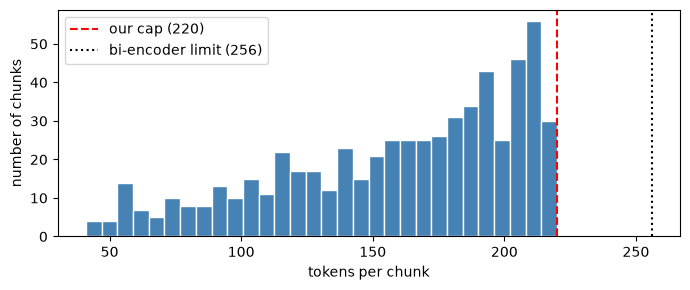


### C0538 | 220 tokens | rules 9.12.4-9.12.4 | pages 87-87
[Netrunner CR v26.03 | 9 Abilities > 9.12 Other Rules and Terminology]
9.12.4. Repeat this process
a. If an ability instructs a player to “repeat this process” without specifying how many times to do so, then that player resolves the ability again, including the instruction to “repeat this process” if it is still applicable.
b. If an ability instructs a player to “repeat this process” a specified number of times, then that player resolves the entire ability, except for the repetition instruction, that many times in a row. The number of repetitions is determined after the first full resolution but before the first repetition, and once the number of repetitions is determined it cannot be changed.
c. Regardless of the number of times an ability is repeated, a checkpoint occurs after each full resolution of the ability’s instructions, before another repetition begins.
d. Each repetition of t

### C0010 | 41 tokens | rules 1.5.1-1.

In [10]:
tokens = [c["n_tokens"] for c in chunks]
print(f"chunks: {len(chunks)} | tokens per chunk: min {min(tokens)}, median {int(np.median(tokens))}, max {max(tokens)}")
print(f"bi-encoder limit: {bi_encoder.max_seq_length} tokens | our cap: {CONFIG['chunk_max_tokens']} | chunks over the cap: {sum(t > CONFIG['chunk_max_tokens'] for t in tokens)}")

# every paragraph of the document must be somewhere in the chunks
all_chunk_text = "\n".join(c["text"] for c in chunks)
missing = [p for u in units for p in u["paras"] if p[:40] not in all_chunk_text]
print("paragraphs missing from the chunks:", len(missing))

print("continuation pieces of long rules:", sum("| continued" in c["text"].split("\n")[0] for c in chunks))
words = r"\b(except|unless|cannot|can't|may not|only if|instead|not allowed|prohibited)\b"
print("chunks with exception / negation wording:", sum(bool(re.search(words, c["text"], re.I)) for c in chunks), "of", len(chunks))

import matplotlib.pyplot as plt
plt.figure(figsize=(7, 3))
plt.hist(tokens, bins=30, color="steelblue", edgecolor="white")
plt.axvline(CONFIG["chunk_max_tokens"], color="red", linestyle="--", label="our cap (220)")
plt.axvline(bi_encoder.max_seq_length, color="black", linestyle=":", label="bi-encoder limit (256)")
plt.xlabel("tokens per chunk"); plt.ylabel("number of chunks"); plt.legend(); plt.tight_layout()
plt.savefig(ROOT / "artifacts/figures/chunk_token_hist.png", dpi=120)
plt.show()

# a few chunks to read
by_size = sorted(chunks, key=lambda c: c["n_tokens"])
samples = [by_size[-1], by_size[0]] + random.Random(CONFIG["seed"]).sample(chunks, 5)
for c in samples:
    print(f"\n### {c['chunk_id']} | {c['n_tokens']} tokens | rules {c['rules']} | pages {c['page_start']}-{c['page_end']}")
    print(c["text"][:900])


### 3.2 Freeze

`chunks.jsonl` and `corpus_manifest.json` (document hash, chunk settings, number of chunks, and the SHA-256 of the chunk file) are written once. All later sections load the chunks with `load_corpus()`, which re-checks that hash. This shows that **both pipelines use exactly the same corpus**. A re-run rebuilds identical chunks.

In [11]:
CHUNKS_PATH = ROOT / "artifacts/chunks.jsonl"
MANIFEST_PATH = ROOT / "artifacts/corpus_manifest.json"

chunks_text = "".join(json.dumps(c, ensure_ascii=False) + "\n" for c in chunks)
chunks_sha256 = hashlib.sha256(chunks_text.encode("utf-8")).hexdigest()

if MANIFEST_PATH.exists():                       # on a re-run, the rebuilt chunks must be identical to the frozen ones
    frozen_hash = json.loads(MANIFEST_PATH.read_text())["chunks_sha256"]
    print("rebuilt corpus identical to the frozen one:", frozen_hash == chunks_sha256)

CHUNKS_PATH.write_text(chunks_text, encoding="utf-8")
MANIFEST_PATH.write_text(json.dumps({
    "document": CONFIG["doc"],
    "body_pages": [FIRST_PAGE, LAST_PAGE],
    "chunk_max_tokens": CONFIG["chunk_max_tokens"],
    "chunk_overlap_tokens": CONFIG["chunk_overlap_tokens"],
    "tokenizer": CONFIG["bi_encoder"],
    "n_chunks": len(chunks),
    "chunks_sha256": chunks_sha256,
}, indent=2) + "\n")

def load_corpus():
    """Every later section loads the chunks through this function, so both pipelines use the same corpus."""
    manifest = json.loads(MANIFEST_PATH.read_text())
    file_hash = hashlib.sha256(CHUNKS_PATH.read_bytes()).hexdigest()
    print("chunks.jsonl matches corpus_manifest.json:", file_hash == manifest["chunks_sha256"])
    return [json.loads(line) for line in CHUNKS_PATH.read_text(encoding="utf-8").splitlines()]

corpus = load_corpus()
print(len(corpus), "chunks | sha256:", chunks_sha256)


rebuilt corpus identical to the frozen one: True
chunks.jsonl matches corpus_manifest.json: True
602 chunks | sha256: abc68239ba744f8090f0b65269e7f540f49ac9998622952a44a5707a79d247b0


## 4. Dense index (Stage 3, Pipeline 1a)

Every chunk is turned into a 384-number vector by the bi-encoder and stored in a FAISS index.
- Vectors are **normalised** (length 1), so the inner product equals the cosine similarity.
- `IndexFlatIP` is an **exact** search. With 602 chunks that is instant and has no approximation error that could confuse the comparison.
- Chunks are embedded exactly as stored, header included, so the bi-encoder sees what the cross-encoder will see.
- The indexing time is measured separately. It happens once, offline, and is **not** part of the per-query latency.

In [12]:
chunk_texts = [c["text"] for c in corpus]

start = time.perf_counter()
embeddings = bi_encoder.encode(chunk_texts, batch_size=32, normalize_embeddings=True, show_progress_bar=False)
indexing_seconds = time.perf_counter() - start

index = faiss.IndexFlatIP(embeddings.shape[1])          # exact search with inner product
index.add(embeddings)
np.save(ROOT / "artifacts/embeddings.npy", embeddings)  # the index can be rebuilt from this file in milliseconds

print("embeddings:", embeddings.shape, embeddings.dtype, "| vectors in the index:", index.ntotal)
print(f"indexing time: {indexing_seconds:.1f} s (done once, offline: not part of the per-query latency)")


embeddings: (602, 384) float32 | vectors in the index: 602
indexing time: 1.5 s (done once, offline: not part of the per-query latency)


### 4.1 Sanity check

If a chunk's own text is used as the query, that chunk must come back first with a cosine close to 1.

In [13]:
# Searching with the exact text of a chunk must return that chunk at rank 1 with a cosine of about 1.0
for i in random.Random(CONFIG["seed"]).sample(range(len(corpus)), 3):
    query_vector = bi_encoder.encode([corpus[i]["text"]], normalize_embeddings=True)
    scores, ids = index.search(query_vector, 1)
    print(f"chunk {corpus[i]['chunk_id']} -> top result {corpus[ids[0][0]]['chunk_id']} | cosine {scores[0][0]:.4f}")


chunk C0114 -> top result C0114 | cosine 1.0000
chunk C0025 -> top result C0025 | cosine 1.0000
chunk C0281 -> top result C0281 | cosine 1.0000


## 5. Retrieval and re-ranking (Stage 4, Pipeline 1b and Pipeline 2a-c)

Two small functions implement the two pipelines:
- **`retrieve(query)`** (Pipeline 1): embed the query, search the index, return the **top 10** chunks by cosine similarity.
- **`rerank(query, hits)`** (Pipeline 2): take **those same 10 candidates**, score all 10 (query, chunk) pairs with the cross-encoder in one batch, and sort by that score, highest first.

Pipeline 1 gives `hits[:3]` to the LLM and Pipeline 2 gives `ranked[:3]`. Both lists come from the same retrieval, so no second search is ever made. The cross-encoder returns a raw score (a logit); it is not turned into a probability.

In [14]:
from dataclasses import dataclass

@dataclass
class Hit:
    chunk_id: str
    bi_rank: int                  # position in the baseline list (1 = best)
    bi_score: float               # cosine similarity from the bi-encoder
    ce_score: float = None        # raw cross-encoder score (filled in by rerank)
    ce_rank: int = None           # position after re-ranking (filled in by rerank)

chunk_by_id = {c["chunk_id"]: c for c in corpus}

def retrieve(query, k=CONFIG["k_retrieve"]):
    """Pipeline 1: embed the query, search the index, return the top k chunks (best first) and the timings."""
    start = time.perf_counter()
    query_vector = bi_encoder.encode([query], normalize_embeddings=True)
    encoded = time.perf_counter()
    scores, ids = index.search(query_vector, k)
    searched = time.perf_counter()

    hits = [Hit(corpus[i]["chunk_id"], rank, float(score))
            for rank, (i, score) in enumerate(zip(ids[0], scores[0]), start=1)]
    return hits, {"encode_ms": (encoded - start) * 1000, "search_ms": (searched - encoded) * 1000}

def rerank(query, hits):
    """Pipeline 2: score all (query, chunk) pairs with the cross-encoder in one batch and sort by that score."""
    start = time.perf_counter()
    pairs = [(query, chunk_by_id[h.chunk_id]["text"]) for h in hits]
    scores = cross_encoder.predict(pairs)
    for h, score in zip(hits, scores):          # the same Hit objects get their score, so the baseline order in the original list is kept
        h.ce_score = float(score)
    ranked = sorted(hits, key=lambda h: (-h.ce_score, h.bi_rank))      # ties keep the bi-encoder order
    for rank, h in enumerate(ranked, start=1):
        h.ce_rank = rank
    return ranked, {"ce_ms": (time.perf_counter() - start) * 1000}

def candidates_table(hits):
    """One row per candidate, in baseline order, with the rank shift."""
    rows = [{"chunk_id": h.chunk_id, "section": chunk_by_id[h.chunk_id]["section_path"].split(" > ")[-1],
             "bi_rank": h.bi_rank, "bi_score": round(h.bi_score, 3),
             "ce_rank": h.ce_rank, "ce_score": round(h.ce_score, 2), "shift": h.bi_rank - h.ce_rank,
             "text": chunk_by_id[h.chunk_id]["text"].split("\n", 1)[1][:110].replace("\n", " ")}
            for h in hits]
    return pd.DataFrame(rows).sort_values("bi_rank")


### 5.1 Demo and checks

One query, with all ten candidates before and after re-ranking. `shift` = baseline rank - re-ranked rank, so a positive number means the chunk moved up. This demo query is only an illustration of the functions; it is not one of the evaluation queries.

In [15]:
query = "What happens if the Corp has to draw a card from R&D but R&D is empty?"

hits, t_retrieve = retrieve(query)             # Pipeline 1: the top 10 by cosine similarity
baseline_top3 = hits[:3]                       # Pipeline 1 gives these three to the LLM

ranked, t_rerank = rerank(query, hits)         # Pipeline 2: the SAME ten candidates, re-sorted by the cross-encoder
reranked_top3 = ranked[:3]                     # Pipeline 2 gives these three to the LLM

print("baseline top 3 :", [h.chunk_id for h in baseline_top3])
print("re-ranked top 3:", [h.chunk_id for h in reranked_top3])
print("retrieval ms:", {k: round(v, 1) for k, v in t_retrieve.items()}, "| re-rank ms:", round(t_rerank["ce_ms"], 1))

pd.set_option("display.max_colwidth", 110, "display.width", 250)
candidates_table(hits)


baseline top 3 : ['C0168', 'C0582', 'C0200']
re-ranked top 3: ['C0168', 'C0582', 'C0583']
retrieval ms: {'encode_ms': 4.6, 'search_ms': 0.3} | re-rank ms: 36.4


,chunk_id,section,bi_rank,bi_score,ce_rank,ce_score,shift,text
0,C0168,4.2 Deck,1,0.582,1,5.28,0,4.2.4. The number of cards in a deck is open information. Any player may count the number of cards in a de...
1,C0582,10.12 Sabotage,2,0.569,2,4.53,0,"10.12.3. In resolving a “sabotage N” effect, the Corp may be required to trash cards from a certain zone i..."
2,C0200,4.8 Set Aside,3,0.520,4,3.28,-1,4.8.7. Facedown cards in the set-aside zone must be kept in distinct groups according to the effect that s...
3,C0583,10.12 Sabotage,4,0.482,3,4.35,1,"b. If there are fewer than N cards in HQ and R&D combined, the Corp trashes all cards from HQ and all card..."
4,C0332,8.3 Arranging and Rearranging Cards,5,0.478,7,1.52,-2,"Example: The Corp plays Cultivate, acting on the top 5 cards of R&D by trashing 1 card, adding 1 card to H..."
5,C0581,10.12 Sabotage,6,0.472,9,-0.35,-3,"Sabotage can be quietly working to undermine a Corp from the inside, organizing protest action, sinking a ..."
6,C0314,7.4 Determining Candidates,7,0.468,6,2.23,1,"Example: The Runner plays The Maker’s Eye and breaches R&D, accessing 2 additional cards. They access Cele..."
7,C0335,8.4 Drawing Cards,8,0.466,5,2.56,3,Example: The Corp takes their mandatory draw while they have Daily Business Show and Raman Rai rezzed. The...
8,C0220,5.6 Steps of the Corp’s Turn,9,0.464,10,-4.78,-1,"5.6.1. During the draw phase, the following steps occur in order: a. The Corp gains their allotted clicks ..."
9,C0311,7.4 Determining Candidates,10,0.462,8,0.06,2,7.4.6. Cards entering a server while a breach is in progress can become candidates. a. If a card enters th...


In [16]:
# Quick checks of the two functions
print("re-ranking returns the same 10 chunks:", sorted(h.chunk_id for h in ranked) == sorted(h.chunk_id for h in hits))
print("re-ranked positions are 1..10 without gaps:", sorted(h.ce_rank for h in ranked) == list(range(1, 11)))

# a query copied from a chunk should bring that chunk to the top
chunk = corpus[300]                            # any chunk will do
hits_2, _ = retrieve(chunk["text"].split("\n", 1)[1])
ranked_2, _ = rerank(chunk["text"].split("\n", 1)[1], hits_2)
print(f"query copied from {chunk['chunk_id']} -> baseline rank 1: {hits_2[0].chunk_id} | re-ranked rank 1: {ranked_2[0].chunk_id}")

print("longest chunk:", max(c["n_tokens"] for c in corpus), "tokens, so a (query, chunk) pair stays far below the cross-encoder limit of 512")


re-ranking returns the same 10 chunks: True
re-ranked positions are 1..10 without gaps: True
query copied from C0300 -> baseline rank 1: C0300 | re-ranked rank 1: C0300
longest chunk: 220 tokens, so a (query, chunk) pair stays far below the cross-encoder limit of 512


## 6. Prompt and generation (Stage 5, Pipeline 1c and Pipeline 2d)

**LLM:** Gemini through the Google AI Studio free tier, model `gemini-3.1-flash-lite` (pinned in `CONFIG`), `temperature = 0`, hidden reasoning set to `MINIMAL`.
- *Why this model:* the larger `gemini-3.6-flash` allows only **20 requests per day** on the free tier, which is too few for 23 queries × 2 answers plus latency measurements. Flash-Lite has a higher free limit. The same model is used for both pipelines, so the comparison stays fair.
- *Why `MINIMAL` reasoning:* Gemini 3.x models can "think" before answering, which makes calls slower and spends the output limit on hidden reasoning. With `MINIMAL`, the whole output limit is used for the answer and answers are more predictable.

**Fair comparison:** both pipelines use **one** `build_prompt()`, the same model, the same temperature and the same output limit. The two prompts differ **only** in which three passages fill the slots `[S1]`-`[S3]`. Passages are listed best first, using each pipeline's own ranking.

The prompt follows the grounded-generation pattern from the lectures: an instruction, labelled evidence, a refusal rule for when the passages do not contain the answer, a citation rule, and the question last.

In [17]:
PROMPT_TEMPLATE = """You answer questions about the Netrunner Comprehensive Rules using ONLY the numbered passages below.
- Put the passage id after every claim, like [S2].
- If the passages do not contain the answer, reply exactly: "The provided passages do not cover this."
- If a passage states an exception, condition or restriction that is relevant to the question, include it.
- Do not use outside knowledge.

PASSAGES:
{passages}

QUESTION: {question}
ANSWER:"""

def build_prompt(question, chunk_ids):
    """The ONE prompt used by both pipelines. Only the three passages (and their order) differ."""
    passages = []
    for number, chunk_id in enumerate(chunk_ids, start=1):
        chunk = chunk_by_id[chunk_id]
        pages = chunk["page_start"] if chunk["page_start"] == chunk["page_end"] else f"{chunk['page_start']}-{chunk['page_end']}"
        body = chunk["text"].split("\n", 1)[1]                    # the header is replaced by the section path below
        passages.append(f"[S{number}] ({chunk['section_path']}, p.{pages}) {body}")
    return PROMPT_TEMPLATE.format(passages="\n".join(passages), question=question)


### 6.1 Calling Gemini, with a cache

`call_gemini()` makes one real call and retries when Google is busy. `generate()` first looks in a cache file (`artifacts/llm_cache.jsonl`), so a prompt is never sent twice: re-running the notebook is free and returns identical answers. The latency section (Section 10) calls `call_gemini()` directly so that real call times are measured, not cache hits.

The API key is read from `.env`; it is not in the code or in any output.

In [18]:
from google import genai
from google.genai import types, errors

client = genai.Client(api_key=os.environ["GEMINI_API_KEY"])      # the key is read from .env, never written in the notebook

def call_gemini(prompt):
    """One real call to Gemini. Returns (answer, seconds). Waits and retries when Google is busy (503) or rate-limited (429)."""
    config = types.GenerateContentConfig(
        temperature=CONFIG["temperature"],
        max_output_tokens=CONFIG["max_output_tokens"],
        thinking_config=types.ThinkingConfig(thinking_level=CONFIG["thinking_level"]),   # no hidden reasoning, so answers are short and fast
    )
    for attempt in range(1, 7):
        try:
            start = time.perf_counter()
            response = client.models.generate_content(model=CONFIG["llm_model"], contents=prompt, config=config)
            return (response.text or "").strip(), time.perf_counter() - start
        except errors.APIError as error:
            if error.code not in (429, 500, 503) or attempt == 6:
                raise
            print(f"Gemini busy or rate-limited (error {error.code}), retrying in {10 * attempt} s ...")
            time.sleep(10 * attempt)

# Answers are cached on disk: the same prompt is never sent twice, so re-running the notebook is free and gives identical answers.
CACHE_PATH = ROOT / "artifacts/llm_cache.jsonl"
cache = {}
if CACHE_PATH.exists():
    for line in CACHE_PATH.read_text(encoding="utf-8").splitlines():
        row = json.loads(line)
        cache[row["key"]] = row["answer"]

def generate(prompt):
    """Answer for a prompt: from the cache if we have it, otherwise from Gemini (and then cached)."""
    key = hashlib.sha256(f"{CONFIG['llm_model']}|{CONFIG['temperature']}|{CONFIG['thinking_level']}|{prompt}".encode()).hexdigest()
    if key not in cache:
        answer, _ = call_gemini(prompt)
        cache[key] = answer
        with open(CACHE_PATH, "a", encoding="utf-8") as f:
            f.write(json.dumps({"key": key, "model": CONFIG["llm_model"], "answer": answer}, ensure_ascii=False) + "\n")
    return cache[key]

print("model:", CONFIG["llm_model"], "| temperature:", CONFIG["temperature"], "| thinking:", CONFIG["thinking_level"], "| cached answers:", len(cache))
print("test call ->", generate("Reply with OK"))            # through the cache, so a re-run does not need Gemini


model: gemini-3.1-flash-lite | temperature: 0.0 | thinking: MINIMAL | cached answers: 6


test call -> OK


### 6.2 Running both pipelines on one query

`run_query()` retrieves the top 10, builds Answer 1 from the top 3 as ranked by the bi-encoder, re-ranks the same 10 for Answer 2, and saves everything (all 10 candidates with both ranks and scores, both prompts, both answers, timings) in `artifacts/results/<qid>.json`. The three queries below only demonstrate that it works.

In [19]:
from dataclasses import asdict

def run_query(qid, question, category=None, gold=None, out_dir=ROOT / "artifacts/results"):
    """Run BOTH pipelines on one question and save everything to <out_dir>/<qid>.json."""
    hits, t_retrieve = retrieve(question)                   # Pipeline 1: top 10 by cosine similarity
    baseline_ids = [h.chunk_id for h in hits[:CONFIG["k_final"]]]

    ranked, t_rerank = rerank(question, hits)               # Pipeline 2: the same 10, re-sorted by the cross-encoder
    reranked_ids = [h.chunk_id for h in ranked[:CONFIG["k_final"]]]

    prompt_1 = build_prompt(question, baseline_ids)
    prompt_2 = build_prompt(question, reranked_ids)
    result = {
        "qid": qid, "query": question, "category": category, "gold": gold,
        "corpus_sha256": json.loads(MANIFEST_PATH.read_text())["chunks_sha256"],
        "candidates": [asdict(h) for h in hits],            # all 10: baseline rank and score, re-ranked rank and score
        "baseline": {"top3": baseline_ids, "prompt": prompt_1, "answer": generate(prompt_1)},
        "reranked": {"top3": reranked_ids, "prompt": prompt_2, "answer": generate(prompt_2)},
        "timings_ms": {**t_retrieve, **t_rerank},
    }
    out_dir.mkdir(parents=True, exist_ok=True)
    (out_dir / f"{qid}.json").write_text(json.dumps(result, indent=2, ensure_ascii=False), encoding="utf-8")
    return result


In [20]:
# Three illustration queries (NOT the evaluation queries). Their files go to artifacts/results/demo/.
demo_queries = [
    ("D1", "Can the Runner jack out during an encounter with ice?"),
    ("D2", "What does it mean for the Corp to rez a card?"),
    ("D3", "Who wins if the Corp must draw a card from R&D and R&D is empty?"),
]
for qid, question in demo_queries:
    result = run_query(qid, question, out_dir=ROOT / "artifacts/results/demo")
    print("=" * 100)
    print(qid, question)
    print("baseline top 3 :", result["baseline"]["top3"], "| re-ranked top 3:", result["reranked"]["top3"])
    print("\nAnswer 1 (baseline):\n" + result["baseline"]["answer"])
    print("\nAnswer 2 (re-ranked):\n" + result["reranked"]["answer"])


D1 Can the Runner jack out during an encounter with ice?
baseline top 3 : ['C0236', 'C0265', 'C0232'] | re-ranked top 3: ['C0265', 'C0266', 'C0258']

Answer 1 (baseline):
The provided passages do not cover this.

Answer 2 (re-ranked):
The provided passages do not cover this.


D2 What does it mean for the Corp to rez a card?
baseline top 3 : ['C0353', 'C0320', 'C0319'] | re-ranked top 3: ['C0320', 'C0353', 'C0319']

Answer 1 (baseline):
To rez an unrezzed card is to turn it faceup [S3]. To resolve the process, the Corp pays the card's rez cost (accounting for any modifiers or additional costs), a checkpoint occurs, and then the Corp turns the card faceup [S2]. For the purposes of meeting trigger conditions, the card is considered to be rezzed at the conclusion of this process [S2]. Before rezzing, the Corp must pay the rez cost, though card abilities can modify or ignore these costs if they state so explicitly [S3d]. Note that agendas cannot be rezzed [S3c].

Answer 2 (re-ranked):
To rez an unrezzed card is to turn it faceup [S3]. To resolve rezzing a card, the Corp must pay the card's rez cost, accounting for any modifiers or additional costs [S1, S3]. After a checkpoint occurs, the Corp turns the card faceup, and the card is considered rezzed at the conclu

D3 Who wins if the Corp must draw a card from R&D and R&D is empty?
baseline top 3 : ['C0168', 'C0582', 'C0200'] | re-ranked top 3: ['C0168', 'C0021', 'C0583']

Answer 1 (baseline):
If the Corp must draw from R&D while it is empty, the Runner wins the game [S1].

Answer 2 (re-ranked):
The Runner wins if the Corp is required to draw a card from R&D but cannot because R&D is empty [S1, S2].


## 7. Query set (Stage 6): finding failure queries

**Goal:** a labelled query set that includes failure queries for every category the assignment names (keyword trap, exception, negation, chunk buried at rank 4-10), plus ordinary control queries.

**Process**
1. **48 candidate queries** were written from the rules text in player language (`queries/queries.yaml`): 10 control, 10 negation, 8 buried, 7 exception and 13 keyword trap (a first round of 6, then 7 more because the first round found no keyword trap that re-ranking fixed).
2. For each, the **gold chunk** (the chunk that answers it) was first found by searching the rules text for the rule itself, **not** by looking at what either retriever returned.
3. Retrieval and re-ranking (no LLM, so it is cheap) are run on every candidate, and the position of the gold chunk is compared before and after re-ranking.
4. The labels were then **audited** (Section 7.2), because a rulebook often states the same rule in more than one place.
5. The whole candidate table is kept, including the queries where re-ranking made no difference or made things worse. The hit rate is part of an honest result.

**From here on, nothing in the pipeline may be changed** (chunking, models, `k`, prompt). Queries are never edited to make a pipeline look better.

> ⚠️ The gold labels were **proposed by Claude** and have not been verified by the student yet (`verified: false`). The student verifies the final set.

In [21]:
import yaml

queries = yaml.safe_load((ROOT / "queries/queries.yaml").read_text(encoding="utf-8"))
candidates_df = pd.DataFrame(queries)
print(len(queries), "candidate queries")
candidates_df.groupby("category").size().to_frame("queries")


48 candidate queries


,queries
category,
buried,8
control,10
exception,7
keyword_trap,13
negation,10


### 7.1 Mining: where does the gold chunk land?

For each query, the best-placed essential gold chunk is looked up in the baseline top 10 and in the re-ranked order. When several chunks are essential, **any one of them answers the question**, so the best-placed one counts.

| Result | Meaning |
|---|---|
| `fixed_by_rerank` | gold at rank 4-10 for the baseline, and in the top 3 after re-ranking |
| `both_ok` | gold in the top 3 both times |
| `hurt_by_rerank` | gold in the top 3 for the baseline, but pushed out by re-ranking |
| `both_fail` | gold in the top 10, but outside the top 3 both times (a ranking failure) |
| `recall_ceiling` | gold not in the top 10 at all: the re-ranker only reorders those 10, so it cannot help |

In [22]:
def classify(bi_rank, ce_rank):
    """Where did the best gold chunk land before and after re-ranking? (rank = None means not in the top 10)"""
    if bi_rank is None:
        return "recall_ceiling"            # not in the top 10: re-ranking cannot help
    if bi_rank > 3 and ce_rank <= 3:
        return "fixed_by_rerank"           # outside the top 3 before, inside after
    if bi_rank <= 3 and ce_rank <= 3:
        return "both_ok"
    if bi_rank <= 3 and ce_rank > 3:
        return "hurt_by_rerank"
    return "both_fail"                     # in the top 10, but outside the top 3 both times

rows = []
for q in queries:
    hits, _ = retrieve(q["query"])
    ranked, _ = rerank(q["query"], hits)
    gold = [h for h in hits if h.chunk_id in q["gold_essential"]]      # gold chunks that are in the top 10
    best = min(gold, key=lambda h: h.bi_rank) if gold else None        # the best-placed one before re-ranking
    best_ce = min(gold, key=lambda h: h.ce_rank) if gold else None     # the best-placed one after re-ranking
    bi_rank = best.bi_rank if best else None
    ce_rank = best_ce.ce_rank if best_ce else None
    rows.append({"qid": q["qid"], "category": q["category"], "gold_bi_rank": bi_rank, "gold_ce_rank": ce_rank,
                 "result": classify(bi_rank, ce_rank), "query": q["query"]})

mining = pd.DataFrame(rows).astype({"gold_bi_rank": "Int64", "gold_ce_rank": "Int64"})   # whole numbers, <NA> when not in the top 10
mining.to_csv(ROOT / "artifacts/candidate_mining.csv", index=False)
mining.drop(columns="query")


,qid,category,gold_bi_rank,gold_ce_rank,result
0,Q01,control,1,2,both_ok
1,Q02,control,7,1,fixed_by_rerank
2,Q03,control,1,1,both_ok
3,Q04,control,2,1,both_ok
4,Q05,control,1,1,both_ok
5,Q06,control,1,1,both_ok
6,Q07,control,1,1,both_ok
7,Q08,control,1,1,both_ok
8,Q09,control,1,1,both_ok
9,Q10,control,<NA>,<NA>,recall_ceiling


In [23]:
print("Result of re-ranking on all", len(mining), "candidate queries (gold chunk placement):")
print(mining["result"].value_counts().to_string())
print()
pd.crosstab(mining["category"], mining["result"])


Result of re-ranking on all 48 candidate queries (gold chunk placement):
result
both_ok            35
fixed_by_rerank     4
recall_ceiling      4
hurt_by_rerank      3
both_fail           2



result,both_fail,both_ok,fixed_by_rerank,hurt_by_rerank,recall_ceiling
category,,,,,
buried,1,4,2,1,0
control,0,8,1,0,1
exception,0,6,0,0,1
keyword_trap,0,10,1,1,1
negation,1,7,0,1,1


### 7.2 Label audit and the final query set

**Why an audit was needed.** The first labels named the one rule the query was written from. But a rulebook often states the same thing in several places (for example, the 7-point win appears in rules 1.7.2a, 1.17.2 and 10.3.1c). If such a second chunk is in the top 3 but not labelled, the table above would wrongly call the baseline a failure.

**How it was done (pooled judgement).** For every query whose result was not `both_ok`, **all 10 candidate chunks were read** and each was judged against one question: *does this chunk, on its own, fully answer the query?* Both pipelines rank exactly these 10 chunks, so judging all of them is fair to both. Adding a missed gold chunk can never turn a `both_ok` result into anything else, so those queries did not need this check. Chunks that only partly answer were recorded as *supporting* and do not count.

**What changed** (all from reading the rule text):

| Query | Added as essential gold | Effect |
|---|---|---|
| Q01 | C0096 (1.17.2), C0552 (10.3.1c) | the baseline already had an answer at rank 1: no longer a "fix" |
| Q15 | C0053 (1.13.6d) | the baseline already had an answer at rank 2: no longer a "fix" |
| Q27 | C0032 (1.10.3b) | the baseline already had an answer at rank 1: no longer a "fix" |
| Q04 | C0256 (6.4.3), C0281 (6.9.2b), C0597 (appendix) | the answer was in the top 3: not a recall-ceiling case |
| Q33 | C0218 (5.5.4c), C0225 (5.7.2a), C0202 (5.1.3) | the answer was in the top 3: not a recall-ceiling case |
| Q29 | C0320 (8.1.2e) | the answer was at rank 4, re-ranked to 1: a genuine fix |
| Q23, Q28, Q32, Q36, Q42 | one more chunk each that restates the rule | result unchanged, except Q28 which became `both_ok` |

Three queries that looked like fixes (Q01, Q15, Q27) turned out not to be. This is reported here so that the remaining fixes can be trusted.

**Final set (23 queries).** Selection rule, fixed before any LLM answer was generated:
- every query where re-ranking changed the outcome: all `fixed_by_rerank`, all `hurt_by_rerank` and all `both_fail`;
- two `recall_ceiling` queries (one exception, one keyword trap) to show the limit of re-ranking;
- the remaining queries are `both_ok` controls that cover every category.

In [24]:
final_ids = [q["qid"] for q in queries if q["final"]]
final_df = mining[mining["qid"].isin(final_ids)]
print(len(final_ids), "final queries out of", len(queries), "candidates")
pd.crosstab(final_df["category"], final_df["result"])


23 final queries out of 48 candidates


result,both_fail,both_ok,fixed_by_rerank,hurt_by_rerank,recall_ceiling
category,,,,,
buried,1,1,2,1,0
control,0,5,1,0,0
exception,0,2,0,0,1
keyword_trap,0,2,1,1,1
negation,1,2,0,1,0
